# AURA: Energy Anomaly Intelligence & Decision Support
### Translating Facility Telemetry into Plain-Language Actionable Insights

```
Facility Energy Data
        ↓
Anomaly Detection Engine (Zone + Time Baselines)
        ↓
🚨 Unusual Pattern Detected (Statistical Z-Score & Deviation)
        ↓
📍 Zone Localization (Pinpoint Clinical / Admin Block)
        ↓
🧠 Explain What Was Observed (Simple Hinglish + English root cause)
        ↓
💡 Actionable Recommendation (Simple, practical steps anyone can execute)
        ↓
👨‍💼 Facility Team Reviews, Inspects & Resolves (Closed-Loop Action Tracking)
```


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Add project root to sys.path so we can import ai_engine
ROOT_DIR = Path('..').resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from ai_engine.energy_anomaly_intelligence import EnergyAnomalyIntelligenceEngine, ZONE_PROFILES

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)

print('AURA AI Engine & Notebook dependencies loaded successfully.')


AURA AI Engine & Notebook dependencies loaded successfully.


## Step 1 & 2: Ingest Data & Run Anomaly Detection Engine
We load the feature-engineered dataset (`data/processed_energy_features.csv`) and run the `EnergyAnomalyIntelligenceEngine` to calculate zone-specific diurnal baselines and detect significant operational deviations.


In [3]:
data_path = Path('../data/processed_energy_features.csv')
df = pd.read_csv(data_path)
df['datetime'] = pd.to_datetime(df['timestamp'], dayfirst=True)

# Initialize and run detection engine
engine = EnergyAnomalyIntelligenceEngine(z_threshold=3.0, min_deviation_pct=30.0)
scored_df = engine.detect_anomalies(df)

anomalies = scored_df[scored_df['is_detected_anomaly']].copy()

print(f'Total Evaluated Readings: {len(scored_df):,}')
print(f'Total Anomalies Detected: {len(anomalies):,} ({len(anomalies)/len(scored_df)*100:.2f}% of data)')
print('\nAnomalies by Severity:\n', anomalies['severity'].value_counts())
print('\nAnomalies by Zone:\n', anomalies['zone_id'].value_counts())


Total Evaluated Readings: 42,720
Total Anomalies Detected: 299 (0.70% of data)

Anomalies by Severity:
 severity
CRITICAL    269
HIGH         29
MEDIUM        1
Name: count, dtype: int64

Anomalies by Zone:
 zone_id
ICU             72
Emergency       70
General_Ward    63
OPD             56
Admin           38
Name: count, dtype: int64


## Step 3 & 4: Visualizing Anomalies Across Hospital Zones (📍 + 🚨)
Below we plot telemetry from two contrasting zones:
1. **Admin Block (Off-Hours Wastage)**: Baseline is low (~15-18 kWh), but night spikes jump to 70-90 kWh.
2. **ICU (Critical Overload)**: Baseline is high (~210 kWh), but equipment surges peak at >350 kWh.


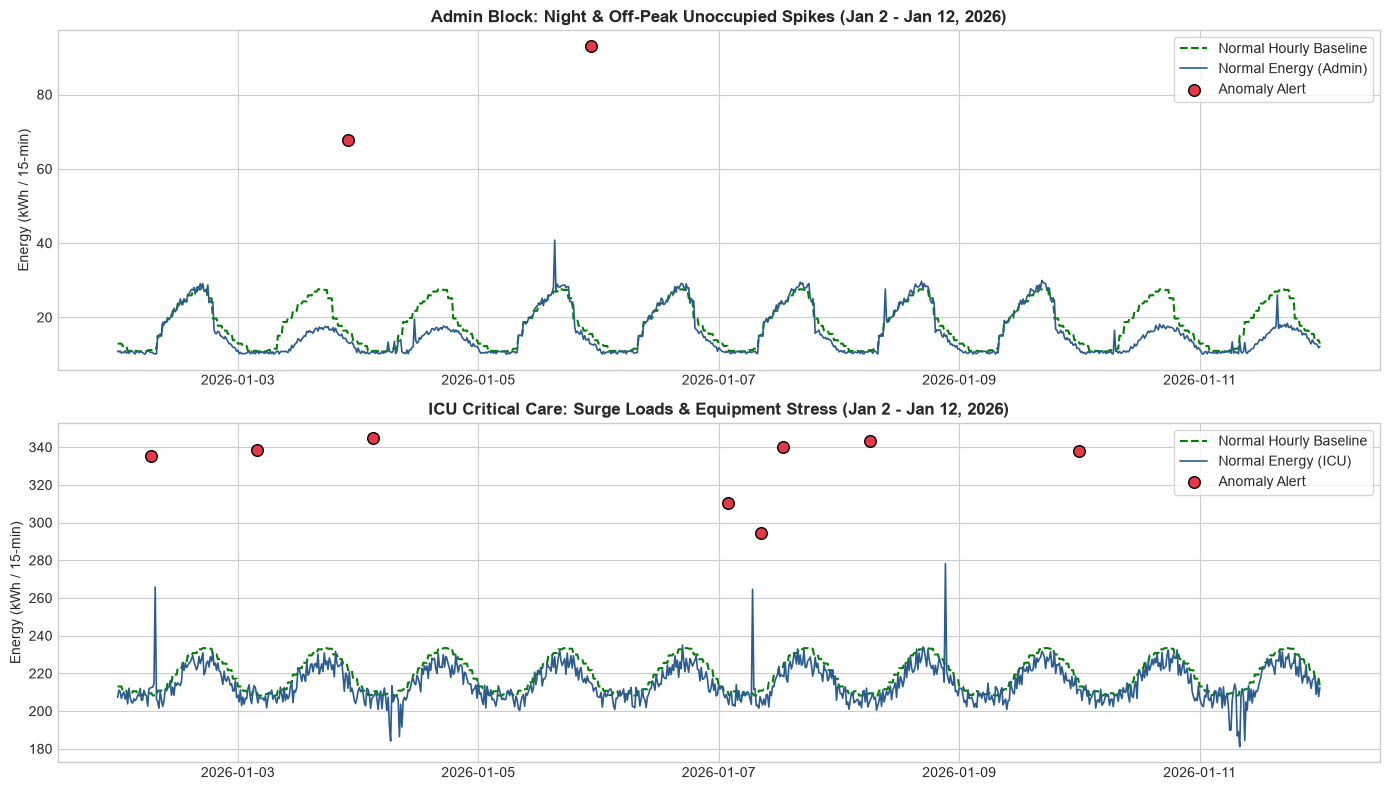

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

# 1. Admin Plot (10-day window)
admin_data = scored_df[(scored_df['zone_id'] == 'Admin') & (scored_df['datetime'] >= '2026-01-02') & (scored_df['datetime'] <= '2026-01-12')].sort_values('datetime')
normal_admin = admin_data[~admin_data['is_detected_anomaly']]
anomaly_admin = admin_data[admin_data['is_detected_anomaly']]

ax1.plot(admin_data['datetime'], admin_data['baseline_mean'], color='green', linestyle='--', linewidth=1.5, label='Normal Hourly Baseline')
ax1.plot(normal_admin['datetime'], normal_admin['energy_kwh'], color='#2b5c8f', linewidth=1.2, label='Normal Energy (Admin)')
ax1.scatter(anomaly_admin['datetime'], anomaly_admin['energy_kwh'], color='#e63946', s=70, edgecolor='black', zorder=5, label='Anomaly Alert')
ax1.set_title('Admin Block: Night & Off-Peak Unoccupied Spikes (Jan 2 - Jan 12, 2026)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Energy (kWh / 15-min)')
ax1.legend(frameon=True, loc='upper right')

# 2. ICU Plot (10-day window)
icu_data = scored_df[(scored_df['zone_id'] == 'ICU') & (scored_df['datetime'] >= '2026-01-02') & (scored_df['datetime'] <= '2026-01-12')].sort_values('datetime')
normal_icu = icu_data[~icu_data['is_detected_anomaly']]
anomaly_icu = icu_data[icu_data['is_detected_anomaly']]

ax2.plot(icu_data['datetime'], icu_data['baseline_mean'], color='green', linestyle='--', linewidth=1.5, label='Normal Hourly Baseline')
ax2.plot(normal_icu['datetime'], normal_icu['energy_kwh'], color='#2b5c8f', linewidth=1.2, label='Normal Energy (ICU)')
ax2.scatter(anomaly_icu['datetime'], anomaly_icu['energy_kwh'], color='#e63946', s=70, edgecolor='black', zorder=5, label='Anomaly Alert')
ax2.set_title('ICU Critical Care: Surge Loads & Equipment Stress (Jan 2 - Jan 12, 2026)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Energy (kWh / 15-min)')
ax2.legend(frameon=True, loc='upper right')

plt.tight_layout()
plt.show()


## Step 5: Explaining Observations (🧠) & Generating Simple Recommendations (💡)
Hospital staff (doctors, nurses, electricians, administrators) should not have to interpret statistical Z-scores or machine learning tensors.
AURA automatically translates detected anomalies into **crystal-clear, everyday Hinglish + English language with practical, numbered checklists**.


In [7]:
# Display structured action tickets across different hospital departments
departments = ['Admin', 'OPD', 'General_Ward', 'Emergency', 'ICU']

for idx, zone in enumerate(departments, start=1):
    sub = anomalies[anomalies['zone_id'] == zone]
    if not sub.empty:
        sample = sub.iloc[0]
        ticket = engine.create_facility_ticket(sample, f'AURA-ENG-2026-{idx:03d}')
        
        print('=' * 80)
        print(f"TICKET ID: {ticket['ticket_id']} | SEVERITY: {ticket['severity']} | DEPT: {ticket['zone_name']}")
        print('=' * 80)
        print(f"Timestamp:   {ticket['timestamp']}")
        print(f"Telemetry:   Observed = {ticket['metrics']['observed_energy_kwh']} kWh | Expected Baseline = {ticket['metrics']['expected_baseline_kwh']} kWh")
        print(f"Excess Load: {ticket['metrics']['excess_energy_kwh']} kWh ({ticket['metrics']['deviation_percentage']} surge) | Room Occupancy: {ticket['metrics']['room_occupancy']}")
        print(f"\n[OBSERVATION] What Was Observed (Plain Explanation):")
        print(f"   {ticket['root_cause_explanation']}")
        print(f"\n[RECOMMENDATION] Actionable Steps (Anyone can follow):")
        for line in ticket['action_recommendation'].split('\n'):
            print(f"   {line}")
        print(f"\n[ASSIGNED] Team: {ticket['assigned_team']} | Status: {ticket['status']}\n")


TICKET ID: AURA-ENG-2026-001 | SEVERITY: CRITICAL | DEPT: Administration & Executive Wing
Timestamp:   03-01-2026 22:00
Telemetry:   Observed = 67.83 kWh | Expected Baseline = 15.54 kWh
Excess Load: 52.29 kWh (+336.5% surge) | Room Occupancy: 0.4%

[OBSERVATION] What Was Observed (Plain Explanation):
   [ALERT] [Off-Hours Spike] Administration & Executive Wing mein raat ke 22:00 baje energy consumption achanak 67.8 kWh ho gaya, jabki normal baseline sirf 15.5 kWh hota hai (+337% extra power). Is time occupancy sirf 0% hai (area lagbhag khali hai), isliye itni zyada power draw hona abnormal hai.

[RECOMMENDATION] Actionable Steps (Anyone can follow):
   [RECOMMENDATION] Step 1: Night guard ya duty electrician turant Admin 2nd floor aur conference room bhejein.
   [RECOMMENDATION] Step 2: Check karein ki meeting room ke central AC chillers aur computer lab strips galti se ON toh nahi reh gaye.
   [RECOMMENDATION] Step 3: Unoccupied cabins ke switches aur decorative hallway lighting ko OF

## Step 6: Facility Team Review & Resolution Simulation (👨‍💼)
Demonstrating the closed-loop resolution workflow:
1. Ticket is flagged as `PENDING_FACILITY_REVIEW`.
2. Duty electrician / biomedical engineer inspects the zone and takes corrective action.
3. Ticket is marked `RESOLVED` with root cause confirmed and energy telemetry verified back to baseline.


In [9]:
sample_ticket = engine.create_facility_ticket(anomalies[anomalies['zone_id'] == 'Admin'].iloc[0], 'AURA-ENG-2026-001')

print('--- BEFORE FACILITY ACTION ---')
print(f"Ticket: {sample_ticket['ticket_id']} | Status: {sample_ticket['status']}")
print(f"Current Consumption: {sample_ticket['metrics']['observed_energy_kwh']} kWh (Excess: {sample_ticket['metrics']['deviation_percentage']})")

# Simulate Facility Action
sample_ticket['status'] = 'RESOLVED'
sample_ticket['action_taken'] = 'Electrician visited Admin 2nd floor; found conference room chiller unit set to continuous manual override. Switched off chiller and corridor lights.'
sample_ticket['verified_by'] = 'Ramesh Kumar (Senior Duty Electrician)'
sample_ticket['post_action_kwh'] = 16.2  # Restored to normal baseline

print('\n--- AFTER FACILITY ACTION (CLOSED-LOOP VERIFICATION) ---')
print(f"Status:        {sample_ticket['status']} [VERIFIED]")
print(f"Action Taken:  {sample_ticket['action_taken']}")
print(f"Verified By:   {sample_ticket['verified_by']}")
print(f"Normalized:    Power dropped from {sample_ticket['metrics']['observed_energy_kwh']} kWh -> {sample_ticket['post_action_kwh']} kWh (Normal baseline restored!)")


--- BEFORE FACILITY ACTION ---
Ticket: AURA-ENG-2026-001 | Status: PENDING_FACILITY_REVIEW
Current Consumption: 67.83 kWh (Excess: +336.5%)

--- AFTER FACILITY ACTION (CLOSED-LOOP VERIFICATION) ---
Status:        RESOLVED [VERIFIED]
Action Taken:  Electrician visited Admin 2nd floor; found conference room chiller unit set to continuous manual override. Switched off chiller and corridor lights.
Verified By:   Ramesh Kumar (Senior Duty Electrician)
Normalized:    Power dropped from 67.83 kWh -> 16.2 kWh (Normal baseline restored!)
